# Algebra / Number Theory：SFT 前后 loss 变化的预实验

**Run：** `math-algebra-numbertheory-qwen25-1p5b-seed42`  
**结果时间（UTC）：** 2026-10-21T17:23:47.726111+00:00  
**模型：** `Qwen/Qwen2.5-1.5B-Instruct`；主报告 checkpoint：step 32。

本 notebook 将实验设置、结果、对照和局限放在一起。两项指标并列考察，不设主次：loss 下降量 ROC-AUC **0.6849**（95% CI 0.6534–0.7160）；相对下降比例 ROC-AUC **0.7007**（95% CI 0.6688–0.7314）。
指标是否优于基线以及长度控制后的表现，见后面的配对比较。

已保存执行输出，直接打开即可查看表格和图。重跑只读取同目录的 `snapshot/`，
不需要 GPU、checkpoint 或原始数据挂载，也不会重新训练模型。
来源路径、时间依据和快照 SHA-256 见 `manifest.json`。

## 1. 问题与评价约定

只在 A1 上做 SFT；A2 是未参与这次 SFT 的 A 域样本，B 是另一个域。
两个模型使用完全相同的 token IDs 和回答 mask，只计算回答正文的平均 token NLL（nats/token）。
A2 为正类，所有排序方向预先固定；A1 诊断样本不参与 A2/B 的分类评价。

下降量和相对下降比例并列考察，不设主次。

- loss 下降量：`delta_loss = L_ref - L_sft`。
- 相对下降比例：`relative_gain = (L_ref - L_sft) / max(L_ref, 1e-6)`。
- 基线：`-L_ref`、`-L_sft`，即 loss 低的样本优先；反向基线在附录单列。
- 95% 区间来自原始分析的 2,000 次按 domain 分层、按 group 重采样的 bootstrap。
  本 notebook 重算 AUC、AP 和 top-k 点估计并与快照交叉核对，直接展示原始区间。

这是**同域识别**预实验，不直接检验被选数据用于后续训练时的实际收益。

In [1]:
import hashlib
import json
import math
import os
import sys
import tempfile
from pathlib import Path

if 'MPLCONFIGDIR' not in os.environ:
    scratch = Path('/dev/shm/data-picking-runtime') if Path('/dev/shm').is_dir() else Path(tempfile.gettempdir()) / 'data-picking-runtime'
    os.environ['MPLCONFIGDIR'] = str(scratch / 'matplotlib')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 100)

In [2]:
candidates = [Path.cwd(), Path.cwd() / 'experiments-analysis' / '2026-10-21_172347Z_math-algebra-numbertheory-qwen25-1p5b-seed42']
HERE = next((p for p in candidates if (p / 'manifest.json').is_file() and (p / 'snapshot').is_dir()), None)
if HERE is None:
    raise FileNotFoundError('请将 notebook 工作目录设为本实验目录，或仓库根目录。')
SNAPSHOT = HERE / 'snapshot'
manifest = json.loads((HERE / 'manifest.json').read_text())
for name, info in manifest['files'].items():
    content = (SNAPSHOT / name).read_bytes()
    assert len(content) == info['bytes'], name
    assert hashlib.sha256(content).hexdigest() == info['sha256'], name

def load_json(name):
    return json.loads((SNAPSHOT / name).read_text())

metrics = load_json('metrics.json')
effective = load_json('effective_config.json')
completed = load_json('training_complete.json')
validation = load_json('validation_summary.json')
df = pd.read_parquet(SNAPSHOT / 'per_example.parquet')
training = pd.read_json(SNAPSHOT / 'train.jsonl', lines=True)
evaluation = df.loc[df['split'].isin(['A2', 'B'])].reset_index(drop=True)
matched_ids = load_json('length_matched_ids.json')
assert df['id'].is_unique
assert len(set(matched_ids)) == len(matched_ids)
assert set(matched_ids) <= set(evaluation['id'])
matched = evaluation.set_index('id').loc[matched_ids].reset_index()
assert len(evaluation) == metrics['main']['examples']
assert set(evaluation['split']) == {'A2', 'B'}
assert completed['global_step'] == metrics['checkpoint_step']
assert metrics['primary_checkpoint'] is True
print(f"快照校验通过；全部逐样本记录 {len(df)} 条，正式评估 {len(evaluation)} 条，长度匹配 {len(matched)} 条。")
print('Python:', sys.executable)

快照校验通过；全部逐样本记录 1152 条，正式评估 1024 条，长度匹配 808 条。
Python: /home/v-guanhechen/data-picking/.venv/bin/python


## 2. 实验设置与数据划分

In [3]:
cfg = effective['config']
settings = [
    ('模型', cfg['model']['name']),
    ('模型 revision', cfg['model']['revision']),
    ('数据源', cfg['data']['name']),
    ('数据 revision', cfg['data']['revision']),
    ('A / B', f"{cfg['data']['a_subset']} / {cfg['data']['b_subset']}"),
    ('划分 seed / 训练 seed', f"{cfg['data']['split_seed']} / {cfg['training']['seed']}"),
    ('训练规模', f"{effective['actual_train_size']} examples; {completed['seen_response_tokens']:,} response tokens"),
    ('训练长度', f"{cfg['training']['epochs']} epoch; {completed['global_step']} optimizer steps"),
    ('有效 batch / 学习率', f"{cfg['training']['effective_batch_size']} / {cfg['training']['learning_rate']}"),
    ('训练精度 / attention', f"{cfg['training']['parameter_dtype']} parameters + {cfg['training']['autocast_dtype']} autocast / {cfg['training']['attention_backend']}"),
    ('打分精度', cfg['scoring']['forward_dtype']),
    ('主报告 checkpoint', completed['global_step']),
]
display(pd.DataFrame(settings, columns=['设置', '值']))
splits = effective['data_summary']['splits']
display(pd.DataFrame([
    {'split': name, '条数': value['examples'], '回答 tokens': value['response_tokens'], **value['level_counts']}
    for name, value in splits.items()
]).set_index('split').fillna(0))
assert splits['A2']['level_counts'] == splits['B']['level_counts']
display(pd.DataFrame(effective['data_summary']['filter_counts']).fillna(0).astype(int).rename_axis('过滤 / 选择状态'))

,设置,值
0,模型,Qwen/Qwen2.5-1.5B-Instruct
1,模型 revision,989aa7980e4cf806f80c7fef2b1adb7bc71aa306
2,数据源,EleutherAI/hendrycks_math
3,数据 revision,21a5633873b6a120296cce3e2df9d5550074f4a3
4,A / B,algebra / number_theory
5,划分 seed / 训练 seed,2026 / 42
6,训练规模,"1024 examples; 138,236 response tokens"
7,训练长度,1 epoch; 32 optimizer steps
8,有效 batch / 学习率,32 / 2e-05
9,训练精度 / attention,float32 parameters + bfloat16 autocast / math


,条数,回答 tokens,Level 3,Level 4,Level 1,Level 2,Level 5
split,,,,,,,
A1,1024,138236,234,234,109,203,244
A2,512,70771,119,119,46,104,124
B,512,88882,119,119,46,104,124


,A,B
过滤 / 选择状态,,
selected,1536,512
eligible,93,345
image_or_diagram,79,3
duplicate_group_member,36,9


A2/B 的难度等级组成完全匹配。按规范化问题及字符 5-gram 相似度分组后，每组保留一个代表，
跨域重复组排除；图形表示、空内容和超长样本按同一规则过滤。
`eligible` 表示过滤后可用但未抽入本轮的样本。官方 test 没有用于这轮训练或打分。
这些措施不能保证排除所有语义重复，也未核验初始模型预训练是否包含 MATH。

## 3. 训练过程与两域 loss 变化

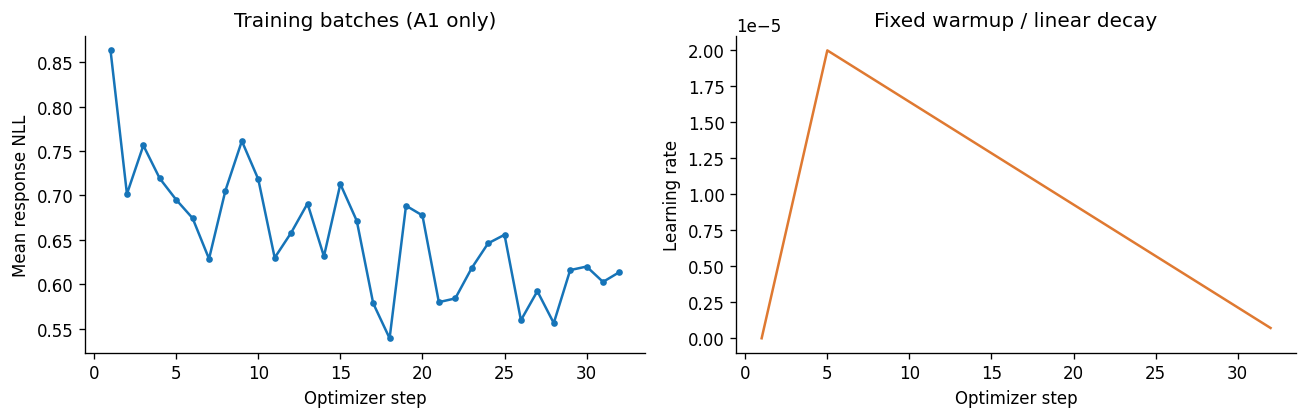

训练 step 记录的耗时合计 97.3 秒；不含模型加载、checkpoint I/O 和评分。


In [4]:
assert training['step'].tolist() == list(range(1, completed['global_step'] + 1))
assert np.isfinite(training[['loss', 'grad_norm']].to_numpy()).all()
assert int(training['response_tokens'].sum()) == completed['seen_response_tokens']
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(training['step'], training['loss'], marker='.', color='#1674B8')
axes[0].set(xlabel='Optimizer step', ylabel='Mean response NLL', title='Training batches (A1 only)')
axes[1].plot(training['step'], training['lr'], color='#DF7931')
axes[1].set(xlabel='Optimizer step', ylabel='Learning rate', title='Fixed warmup / linear decay')
fig.tight_layout()
plt.show()
plt.close(fig)
print(f"训练 step 记录的耗时合计 {training['seconds'].sum():.1f} 秒；不含模型加载、checkpoint I/O 和评分。")

每一步的 batch 内容不同，因此训练曲线不等于固定评估集上的学习曲线。下面比较相同样本在两个模型下的 loss；A1 只展示固定的 128 条训练诊断样本。

,条数,ref NLL,SFT NLL,平均下降量,loss 下降样本比例
split,,,,,
A1_diagnostic,128,0.8214,0.5154,0.3060,1.0000
A2,512,0.8093,0.6374,0.1719,0.9746
B,512,0.8967,0.7959,0.1008,0.8809


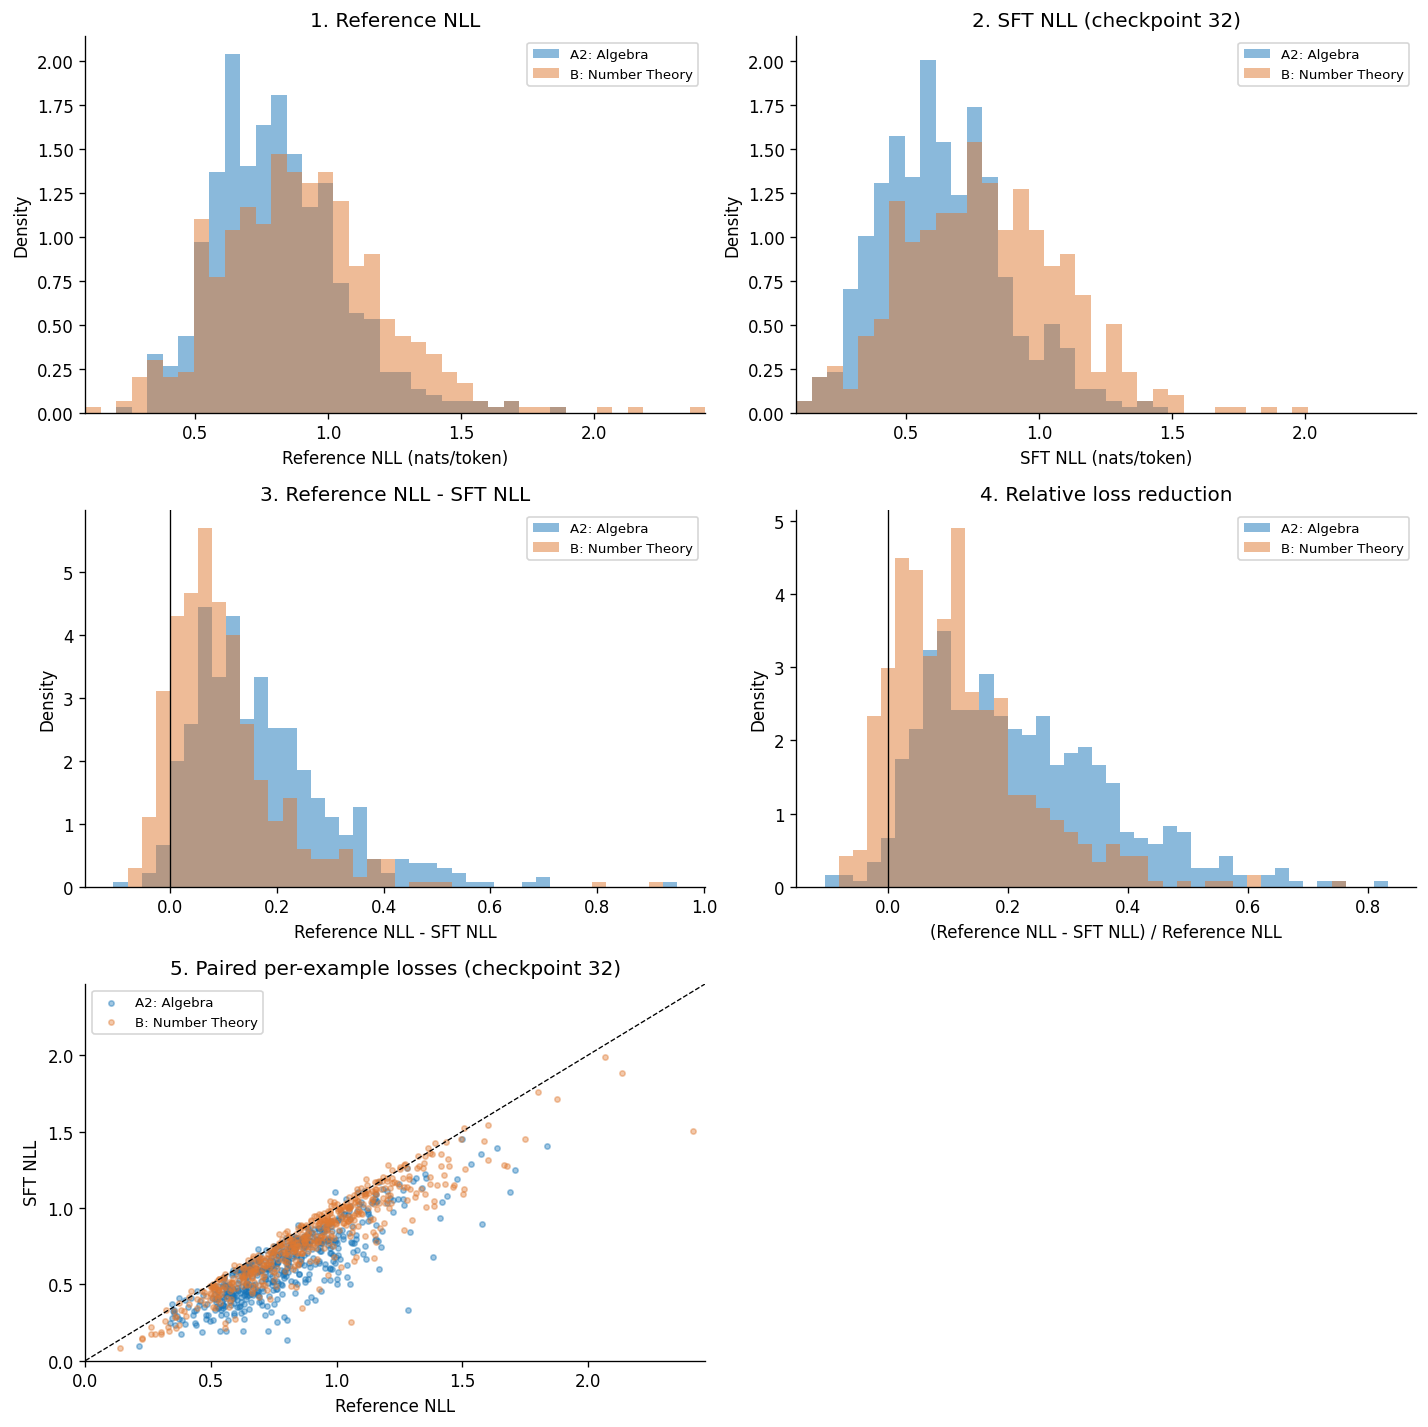

In [5]:
loss_table = pd.DataFrame([
    {'split': name, '条数': len(group), 'ref NLL': group['ref_mean_nll'].mean(),
     'SFT NLL': group['sft_mean_nll'].mean(), '平均下降量': group['delta_loss'].mean(),
     'loss 下降样本比例': (group['delta_loss'] > 0).mean()}
    for name, group in df.groupby('split', sort=True)
]).set_index('split')
display(loss_table.round(4))
colors = {'A': '#1674B8', 'B': '#DF7931'}
domain_names = {'A': 'A2: ' + cfg['data']['a_subset'].replace('_', ' ').title(),
                'B': 'B: ' + cfg['data']['b_subset'].replace('_', ' ').title()}
scoring_steps = evaluation['checkpoint_step'].unique()
assert len(scoring_steps) == 1, 'Expected one SFT checkpoint for the paired comparison'
sft_step = int(scoring_steps[0])
assert sft_step == completed['global_step']

fig = plt.figure(figsize=(12, 12))
grid = fig.add_gridspec(3, 2)
axes = [fig.add_subplot(grid[row, col]) for row in range(2) for col in range(2)]
axes.append(fig.add_subplot(grid[2, 0]))

# Use the same NLL bins for both models and both domains.
nll_bins = np.histogram_bin_edges(
    evaluation[['ref_mean_nll', 'sft_mean_nll']].to_numpy().ravel(), bins=40)
distributions = [
    ('ref_mean_nll', 'Reference NLL (nats/token)', '1. Reference NLL'),
    ('sft_mean_nll', 'SFT NLL (nats/token)', f'2. SFT NLL (checkpoint {sft_step})'),
    ('delta_loss', 'Reference NLL - SFT NLL', '3. Reference NLL - SFT NLL'),
    ('relative_gain', '(Reference NLL - SFT NLL) / Reference NLL', '4. Relative loss reduction'),
]
for ax, (column, xlabel, title) in zip(axes[:4], distributions):
    bins = nll_bins if column in {'ref_mean_nll', 'sft_mean_nll'} else np.histogram_bin_edges(evaluation[column], bins=40)
    for domain, group in evaluation.groupby('domain'):
        ax.hist(group[column], bins=bins, density=True, alpha=0.5,
                label=domain_names[domain], color=colors[domain])
    if column in {'delta_loss', 'relative_gain'}:
        ax.axvline(0, color='black', linewidth=0.8)
    ax.set(xlabel=xlabel, ylabel='Density', title=title)

nll_ymax = max(ax.get_ylim()[1] for ax in axes[:2])
for ax in axes[:2]:
    ax.set_xlim(nll_bins[0], nll_bins[-1])
    ax.set_ylim(0, nll_ymax)

for domain, group in evaluation.groupby('domain'):
    axes[4].scatter(group['ref_mean_nll'], group['sft_mean_nll'], s=10, alpha=0.4,
                    label=domain_names[domain], color=colors[domain])
bound = evaluation[['ref_mean_nll', 'sft_mean_nll']].to_numpy().max() * 1.02
axes[4].plot([0, bound], [0, bound], 'k--', linewidth=0.8)
axes[4].set(xlabel='Reference NLL', ylabel='SFT NLL',
            title=f'5. Paired per-example losses (checkpoint {sft_step})',
            xlim=(0, bound), ylim=(0, bound))
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

## 4. 能否把 A2 排在 B 前面？

In [6]:
score_keys = ['delta_loss', 'relative_gain', 'neg_ref_loss', 'neg_sft_loss']
score_labels = {'delta_loss': 'loss 下降量', 'relative_gain': '相对下降比例',
                'neg_ref_loss': 'ref loss，低值优先', 'neg_sft_loss': 'SFT loss，低值优先'}

def point_metrics(frame, key, ties):
    y = (frame['domain'] == 'A').to_numpy(dtype=int)
    scores = frame[key].to_numpy()
    order = np.lexsort((ties, -scores))
    return {'roc_auc': roc_auc_score(y, scores),
            'precision_top_10pct': y[order[:math.ceil(len(y) * .1)]].mean(),
            'precision_top_20pct': y[order[:math.ceil(len(y) * .2)]].mean()}

for frame, stored in [(evaluation, metrics['main']), (matched, metrics['length_matched'])]:
    ties = np.random.default_rng(cfg['analysis']['bootstrap_seed'] + 1).random(len(frame))
    for key in score_keys:
        for name, value in point_metrics(frame, key, ties).items():
            np.testing.assert_allclose(value, stored['scores'][key][name], rtol=0, atol=1e-12)

def interval(values):
    return f'[{values[0]:.4f}, {values[1]:.4f}]'

def metric_table(result, keys=score_keys):
    records = []
    for key in keys:
        row = result['scores'][key]
        records.append({'排序指标': score_labels.get(key, key), 'ROC-AUC': round(row['roc_auc'], 4),
                        'Top 10% A2': f"{row['precision_top_10pct']:.1%}",
                        'Top 20% A2': f"{row['precision_top_20pct']:.1%}"})
    return pd.DataFrame(records).set_index('排序指标')

display(metric_table(metrics['main']))
print('原始池和长度匹配池的 AUC、top-k 点估计均已重新计算，并与快照一致。')
print(f"原始池 top 10% 取前 {math.ceil(len(evaluation) * .1)} 条；A2/B 各占一半，随机 A2 占比期望为 50%。")

,ROC-AUC,Top 10% A2,Top 20% A2
排序指标,,,
loss 下降量,0.6849,70.9%,72.7%
相对下降比例,0.7007,77.7%,76.6%
ref loss，低值优先,0.5922,45.6%,56.1%
SFT loss，低值优先,0.6645,68.0%,67.8%


原始池和长度匹配池的 AUC、top-k 点估计均已重新计算，并与快照一致。
原始池 top 10% 取前 103 条；A2/B 各占一半，随机 A2 占比期望为 50%。


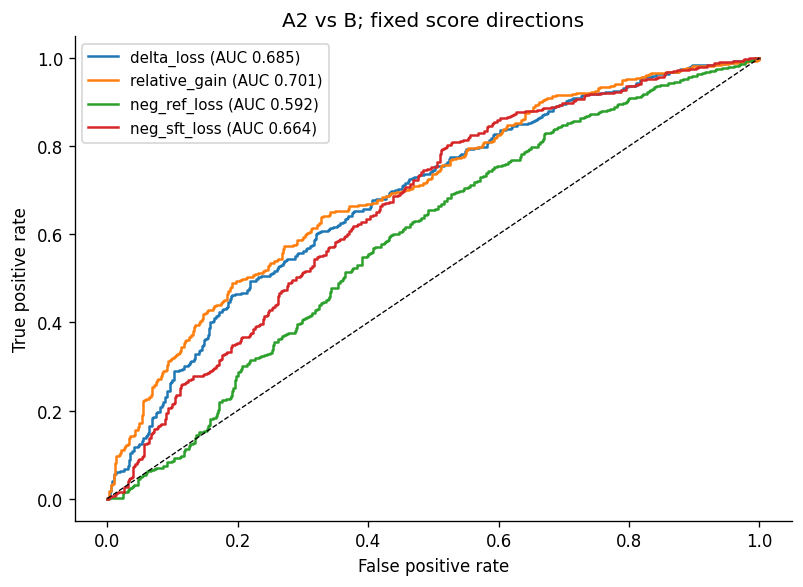

In [7]:
y = (evaluation['domain'] == 'A').to_numpy(dtype=int)
fig, ax = plt.subplots(figsize=(6.8, 5))
for key in score_keys:
    fpr, tpr, _ = roc_curve(y, evaluation[key])
    ax.plot(fpr, tpr, label=f"{key} (AUC {metrics['main']['scores'][key]['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], 'k--', linewidth=0.8)
ax.set(xlabel='False positive rate', ylabel='True positive rate', title='A2 vs B; fixed score directions')
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()
plt.close(fig)

## 5. 长度控制及相对基线的增益

原始分析按混合池的 prompt/response 长度四分位建立联合分桶，每桶从两域各取相同数量，
未使用模型分数挑样本。下面读取保存的匹配 ID，展示同一份控制样本。
匹配改变了评估人群，且分桶不能保证完全消除长度或其他混杂因素。

In [8]:
print(f"匹配保留 {len(matched)}/{len(evaluation)} 条（{len(matched)/len(evaluation):.1%}）。")
display(pd.DataFrame({'原始池': evaluation.groupby('domain').size(),
                      '长度匹配': matched.groupby('domain').size()}))
display(metric_table(metrics['length_matched']))
length_rows = []
for pool, result in [('原始池', metrics['main']), ('长度匹配', metrics['length_matched'])]:
    for column, values in result['length_baselines'].items():
        length_rows.append({'评估集': pool, '长度特征': column, '+长度 AUC': values['positive_auc'], '-长度 AUC': values['negative_auc']})
display(pd.DataFrame(length_rows).round(4))

匹配保留 808/1024 条（78.9%）。


,原始池,长度匹配
domain,,
A,512,404
B,512,404


,ROC-AUC,Top 10% A2,Top 20% A2
排序指标,,,
loss 下降量,0.6524,66.7%,67.9%
相对下降比例,0.6770,76.5%,74.1%
ref loss，低值优先,0.6138,44.4%,55.6%
SFT loss，低值优先,0.6707,69.1%,64.2%


,评估集,长度特征,+长度 AUC,-长度 AUC
0,原始池,prompt_tokens,0.5510,0.4490
1,原始池,response_tokens,0.4099,0.5901
2,长度匹配,prompt_tokens,0.5006,0.4994
3,长度匹配,response_tokens,0.4885,0.5115


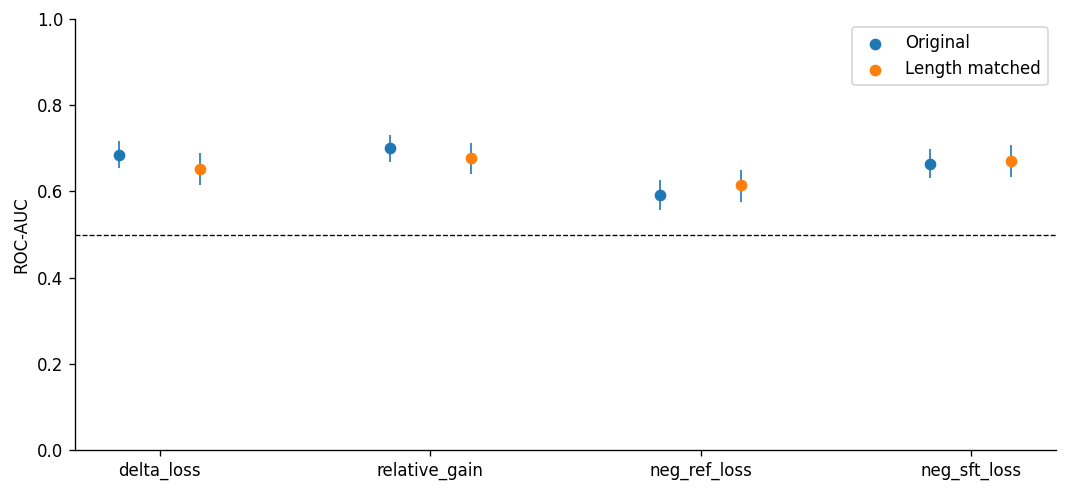

,评估集,比较,AUC 差,配对 95% CI,区间覆盖 0
0,原始池,delta_loss − neg_ref_loss,0.0927,"[0.0394, 0.1450]",False
1,原始池,delta_loss − neg_sft_loss,0.0204,"[-0.0228, 0.0629]",True
2,长度匹配,delta_loss − neg_ref_loss,0.0387,"[-0.0192, 0.0966]",True
3,长度匹配,delta_loss − neg_sft_loss,-0.0183,"[-0.0646, 0.0281]",True


In [9]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for shift, pool, result in [(-0.15, 'Original', metrics['main']), (.15, 'Length matched', metrics['length_matched'])]:
    positions = np.arange(len(score_keys)) + shift
    values = [result['scores'][k]['roc_auc'] for k in score_keys]
    ax.scatter(positions, values, label=pool, zorder=3)
    for position, key in zip(positions, score_keys):
        low, high = result['scores'][key]['roc_auc_ci95']
        ax.vlines(position, low, high, linewidth=1)
ax.axhline(.5, linestyle='--', color='black', linewidth=.8)
ax.set(xticks=np.arange(len(score_keys)), xticklabels=score_keys, ylabel='ROC-AUC', ylim=(0, 1))
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

comparisons = []
for pool, result in [('原始池', metrics['main']), ('长度匹配', metrics['length_matched'])]:
    for baseline in ['neg_ref_loss', 'neg_sft_loss']:
        value = result['paired_delta_auc_minus_baseline'][baseline]
        low, high = value['ci95']
        comparisons.append({'评估集': pool, '比较': 'delta_loss − ' + baseline,
                            'AUC 差': round(value['difference'], 4), '配对 95% CI': interval(value['ci95']),
                            '区间覆盖 0': low <= 0 <= high})
display(pd.DataFrame(comparisons))

## 6. 结论与边界

In [10]:
texts = []
for key in ['delta_loss', 'relative_gain']:
    value = metrics['main']['scores'][key]
    lo, hi = value['roc_auc_ci95']
    signal = ('在固定方向上有区分信号' if lo > .5 else
              '区分方向与预设假设相反，没有事后翻转分数' if hi < .5 else
              '区间覆盖 0.5，尚无稳定的区分证据')
    texts.append(f"{score_labels[key]}：AUC {value['roc_auc']:.4f}，95% CI {interval(value['roc_auc_ci95'])}；{signal}。")
a2, b = metrics['loss_summary']['A2'], metrics['loss_summary']['B']
texts.append(f"A2 平均 NLL：{a2['ref_mean_nll']['mean']:.4f} → {a2['sft_mean_nll']['mean']:.4f}；"
             f"B：{b['ref_mean_nll']['mean']:.4f} → {b['sft_mean_nll']['mean']:.4f}。")
if a2['delta_loss']['mean'] > 0 and b['delta_loss']['mean'] > 0:
    texts.append('两个域的平均 loss 都下降，区分效果没有依赖 B 的平均 loss 恶化。')
for key in ['delta_loss', 'relative_gain']:
    v = metrics['length_matched']['scores'][key]
    texts.append(f"长度匹配后，{score_labels[key]} AUC 为 {v['roc_auc']:.4f}，95% CI {interval(v['roc_auc_ci95'])}。")
for label, result, baseline in [('loss 下降量在原始池中与 SFT loss 比较', metrics['main'], 'neg_sft_loss'),
                                 ('loss 下降量在长度匹配后与 ref loss 比较', metrics['length_matched'], 'neg_ref_loss')]:
    value = result['paired_delta_auc_minus_baseline'][baseline]
    lo, hi = value['ci95']
    if lo <= 0 <= hi:
        texts.append(f"{label}：配对区间覆盖 0，额外区分收益尚不确定。")
    else:
        texts.append(f"{label}：AUC 差 {value['difference']:.4f}，95% CI {interval(value['ci95'])}。")
best = max(score_keys, key=lambda k: metrics['main']['scores'][k]['roc_auc'])
texts.append(f"本轮 {score_labels[best]} 的 AUC 点估计最高；这不自动证明它显著优于其他指标。")
display(Markdown('\n\n'.join(texts)))

loss 下降量：AUC 0.6849，95% CI [0.6534, 0.7160]；在固定方向上有区分信号。

相对下降比例：AUC 0.7007，95% CI [0.6688, 0.7314]；在固定方向上有区分信号。

A2 平均 NLL：0.8093 → 0.6374；B：0.8967 → 0.7959。

两个域的平均 loss 都下降，区分效果没有依赖 B 的平均 loss 恶化。

长度匹配后，loss 下降量 AUC 为 0.6524，95% CI [0.6150, 0.6884]。

长度匹配后，相对下降比例 AUC 为 0.6770，95% CI [0.6408, 0.7131]。

loss 下降量在原始池中与 SFT loss 比较：配对区间覆盖 0，额外区分收益尚不确定。

loss 下降量在长度匹配后与 ref loss 比较：配对区间覆盖 0，额外区分收益尚不确定。

本轮 相对下降比例 的 AUC 点估计最高；这不自动证明它显著优于其他指标。

本轮只有一个模型、一个训练 seed 和一次数据划分；bootstrap 区间不包含训练随机性。
平衡评估池上的 AP/top-k 占比也不能直接外推到其他 A/B 比例的候选池。

后续可做（本轮未运行）：固定方案补独立 seed/划分，再在未参与选择的 A_test 上比较
按不同分数和随机方法选数后的实际训练收益，匹配训练 token 预算。

## 7. 验证记录与原始产物

In [11]:
display(pd.DataFrame([
    ('保存 optimizer / 自动恢复', f"{effective['save_optimizer']} / {effective['auto_resume']}"),
    ('真实续训检查', validation['real_resume']['passed']),
    ('核心 / 分析测试', f"{validation['unit_tests']['core_passed']} / {validation['unit_tests']['analysis_passed']}"),
    ('同模型重复评分最大差', validation['scoring_sanity']['identical_model_max_delta']),
    ('batch / padding 最大差', validation['scoring_sanity']['batch_padding_max_delta']),
    ('相对下降分母保护触发数', metrics['relative_gain_denominator_clamps']),
], columns=['检查', '结果']))
print('原始 run：', manifest['source_run_dir'])
print('最终 checkpoint：', completed['checkpoint'])
print('训练 fingerprint：', effective['training_fingerprint'])
print('时间来源：', manifest['timestamp_basis'])
print('快照文件 SHA-256：')
display(pd.DataFrame([{'文件': name, 'bytes': info['bytes'], 'SHA-256': info['sha256']}
                       for name, info in manifest['files'].items()]).set_index('文件'))

,检查,结果
0,保存 optimizer / 自动恢复,True / True
1,真实续训检查,True
2,核心 / 分析测试,4 / 2
3,同模型重复评分最大差,0.0
4,batch / padding 最大差,0.000003
5,相对下降分母保护触发数,0


原始 run： /mnt/tianzhu_hot/data-picking/runs/math-algebra-numbertheory-qwen25-1p5b-seed42
最终 checkpoint： /mnt/tianzhu_hot/data-picking/runs/math-algebra-numbertheory-qwen25-1p5b-seed42/checkpoints/step-000032-1d6e5f24
训练 fingerprint： 22d1d362f09e21e1ab1995af3261db33a10ee4573549c0cd623a64d0610ab1be
时间来源： metrics/metrics.json filesystem modification time captured at first export; proxy for original analysis completion, not export time
快照文件 SHA-256：


,bytes,SHA-256
文件,,
metrics.json,16952,db88b2eae90bc49c738005846306d3312e932d2405de8e3ff0f998b1c0906c1f
per_example.parquet,340681,1c52b3d31d3ec20df36a740495e8770a457ce86fe8f55aeab49960d7d2a4eec2
length_matched_ids.json,21108,15ac0a9c155195b4e2cdde6abd36d16b421154b3fa62960592e41cc4565163ca
effective_config.json,37891,77b1ac90935052496f3e256faf7581368cacc668a53731abcdaa5008d1326676
training_complete.json,275,e412bde65bca5db9f5d373fe911ffe428fa7fe92e1745536ea3210a6e50237bb
validation_summary.json,1510,5c094b764cf10619fa5f371ec792c650febfee9c877a2e75e6c29f7eb9a57bcf
train.jsonl,5959,ed7d71c19a71272f636aa7f510f28718b9983d672a407ac1cef542803e9595e3


训练在当前本地 PyTorch/CUDA 环境中固定使用 SDPA math 后端，避免自动后端在检查中出现的非有限梯度。
评分使用完整 float32，因为 bf16 在不同 batch/padding 下曾出现约 0.0047 nats/token 的差异。
这些数值修正发生在正式训练和域区分分析之前，没有依据 A2/B 的效果调整超参数。

模型权重、optimizer、数据下载和 token 缓存保留在原始挂载。
本目录只包含用于 review 的 notebook 和小体积结果快照。

## 附录：预先规定的反向原始 loss 基线

In [12]:
display(metric_table(metrics['main'], keys=['pos_ref_loss', 'pos_sft_loss']))

,ROC-AUC,Top 10% A2,Top 20% A2
排序指标,,,
pos_ref_loss,0.4078,30.1%,33.7%
pos_sft_loss,0.3355,22.3%,25.4%
